#### Thư viện và cấu hình

In [1]:
from pathlib import Path
import json
import re
import unicodedata
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import loguniform, randint
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score,
                             roc_auc_score, RocCurveDisplay)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold,
                                     cross_validate)
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
CV_FOLDS = 5
N_ITER_SEARCH = 8  # tăng lên 15–25 nếu máy đủ mạnh
N_JOBS = -1         # đổi thành 2 nếu máy thiếu RAM
LABELS = ['negative', 'positive']


ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_PATH = ROOT / 'data' / 'raw' / 'shopee_reviews_dataset.jsonl'
SPLIT_PATH = ROOT / 'results' / 'data_splits.csv'
OUTPUT_DIR = ROOT / 'results' / 'milestone2'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('Project root:', ROOT.resolve())
print('Dataset exists:', DATA_PATH.exists())
print('Split exists:', SPLIT_PATH.exists())

Project root: D:\Product Review Sentiment Analyst
Dataset exists: True
Split exists: True


#### Tiền xử lý thống nhất với Milestone 1

In [2]:
NEGATION_MAP = {'ko': 'không', 'k': 'không', 'khum': 'không'}
NEGATION_PATTERN = re.compile(r'\b(?:ko|k|khum)\b', flags=re.IGNORECASE)
URL_PATTERN = re.compile(r'https?://\S+|www\.\S+', flags=re.IGNORECASE)
WHITESPACE_PATTERN = re.compile(r'\s+')

def preprocess_text(text):
    if pd.isna(text):
        return ''
    text = unicodedata.normalize('NFC', str(text)).lower()
    text = URL_PATTERN.sub(' ', text)
    text = NEGATION_PATTERN.sub(lambda m: NEGATION_MAP[m.group(0)], text)
    return WHITESPACE_PATTERN.sub(' ', text).strip()


#### Tải dữ liệu và khôi phục split cố định

In [5]:
if not DATA_PATH.exists() or not SPLIT_PATH.exists():
    raise FileNotFoundError('Thiếu dataset hoặc results/data_splits.csv từ Milestone 1.')

records = []
with DATA_PATH.open('r', encoding='utf-8') as f:
    for line_number, line in enumerate(f, start=1):
        if line.strip():
            records.append(json.loads(line))
raw = pd.DataFrame(records)
splits = pd.read_csv(SPLIT_PATH, dtype={'id': str, 'split': str, 'label': str})
raw['id'] = raw['id'].astype(str)

required_raw = {'id', 'review', 'label'}
required_splits = {'id', 'split', 'label'}
assert required_raw.issubset(raw.columns), f'Dataset thiếu: {required_raw - set(raw.columns)}'
assert required_splits.issubset(splits.columns), f'Split thiếu: {required_splits - set(splits.columns)}'
assert raw['id'].is_unique, 'ID dataset không duy nhất: cần kiểm tra lại.'
assert splits['id'].is_unique, 'ID split bị trùng.'

splits['split'] = splits['split'].str.strip().str.lower().replace({'validation': 'val'})
assert splits['split'].notna().all(), 'Có tên split bị thiếu.'
assert set(splits['split']) == {'train', 'val', 'test'}, 'Tên split phải là train, val, test.'
assert set(splits['label']).issubset(set(LABELS)), 'Nhãn ngoài positive/negative.'

# inner join theo ID; kiểm tra chặt để không vô tình thay đổi tập dữ liệu.
df = splits.merge(raw[['id', 'review', 'label']], on='id', how='left',
                  validate='one_to_one', suffixes=('_saved', '_raw'), indicator=True)
assert (df['_merge'] == 'both').all(), 'Một số ID split không tìm thấy trong dataset.'
assert (df['label_saved'] == df['label_raw']).all(), 'Nhãn thay đổi so với Milestone 1.'
assert df['review'].notna().all(), 'Review rỗng.'
df = df.rename(columns={'label_saved': 'label'}).drop(columns=['label_raw', '_merge'])

train = df.loc[df['split'] == 'train'].copy()
val = df.loc[df['split'] == 'val'].copy()
test = df.loc[df['split'] == 'test'].copy()  # CHỈ kiểm tra kích thước; KHÔNG dự đoán

X_train, y_train = train['review'].astype(str), train['label']
X_val, y_val = val['review'].astype(str), val['label']
print('Train / Validation / Test:', len(train), len(val), len(test))
assert len(df) == 9595, 'Số mẫu khác Milestone 1 (9595); kiểm tra lại file split.'
assert (len(train), len(val), len(test)) == (6715, 1440, 1440)

# Kiểm tra giao nhau sau chuẩn hóa (exact-match; không thay thế near-duplicate audit).
sets = [set(part['review'].map(preprocess_text)) for part in (train, val, test)]
assert not (sets[0] & sets[1] or sets[0] & sets[2] or sets[1] & sets[2]),     'Phát hiện review trùng chuẩn hóa giữa các tập!'
display(df.groupby(['split', 'label']).size().unstack(fill_value=0))

Train / Validation / Test: 6715 1440 1440


label,negative,positive
split,,
test,895,545
train,4171,2544
val,895,545


#### Xây dựng Pipeline cho ba thuật toán

In [6]:
def make_pipeline(classifier):
    return Pipeline([
        ('tfidf', TfidfVectorizer(
            preprocessor=preprocess_text,
            ngram_range=(1, 2), min_df=2, max_df=0.95,
            sublinear_tf=True
        )),
        ('classifier', classifier),
    ])

models = {
    'MultinomialNB': make_pipeline(MultinomialNB()),
    'LogisticRegression': make_pipeline(LogisticRegression(
        max_iter=2000, random_state=RANDOM_STATE
    )),
    'RandomForest': make_pipeline(RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=1
    )),
}

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
scoring = {'accuracy': 'accuracy', 'precision_macro': 'precision_macro',
           'recall_macro': 'recall_macro', 'f1_macro': 'f1_macro',
           'roc_auc': 'roc_auc'}
print('Algorithms:', ', '.join(models))

Algorithms: MultinomialNB, LogisticRegression, RandomForest


#### Cross-Validation trên Train (chưa tuning)

In [7]:
cv_rows = []
for name, pipeline in models.items():
    print(f'Cross-validating: {name}')
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring,
                            n_jobs=N_JOBS, error_score='raise')
    row = {'model': name}
    for metric in scoring:
        row[f'{metric}_mean'] = scores[f'test_{metric}'].mean()
        row[f'{metric}_std'] = scores[f'test_{metric}'].std()
    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows).sort_values('f1_macro_mean', ascending=False)
display(cv_results.round(4))
cv_results.to_csv(OUTPUT_DIR / 'cross_validation_results.csv', index=False)

Cross-validating: MultinomialNB
Cross-validating: LogisticRegression
Cross-validating: RandomForest


,model,accuracy_mean,accuracy_std,precision_macro_mean,precision_macro_std,recall_macro_mean,recall_macro_std,f1_macro_mean,f1_macro_std,roc_auc_mean,roc_auc_std
1,LogisticRegression,0.9315,0.0112,0.9301,0.0115,0.9238,0.0127,0.9267,0.0121,0.9789,0.0041
0,MultinomialNB,0.9290,0.0086,0.9271,0.0095,0.9214,0.0090,0.9240,0.0092,0.9778,0.0035
2,RandomForest,0.9124,0.0082,0.9078,0.0085,0.9058,0.0094,0.9067,0.0089,0.9686,0.0047


#### Tối ưu siêu tham số bằng RandomizedSearchCV

In [8]:
param_distributions = {
    'MultinomialNB': {
        'tfidf__ngram_range': [(1, 1), (1, 2)],
        'tfidf__min_df': [2, 3, 5],
        'classifier__alpha': loguniform(0.01, 10),
    },
    'LogisticRegression': {
        'tfidf__ngram_range': [(1, 1), (1, 2)],
        'tfidf__min_df': [2, 3, 5],
        'classifier__C': loguniform(0.1, 30),
        'classifier__class_weight': [None, 'balanced'],
    },
    'RandomForest': {
        'tfidf__ngram_range': [(1, 1), (1, 2)],
        'tfidf__min_df': [2, 3, 5],
        'classifier__n_estimators': [100, 200, 300],
        'classifier__max_depth': [None, 20, 40],
        'classifier__min_samples_leaf': [1, 2, 4],
        'classifier__max_features': ['sqrt', 0.2],
    },
}

searches = {}
search_rows = []
for name, pipeline in models.items():
    print(f'Optimizing: {name}')
    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_distributions[name],
        n_iter=N_ITER_SEARCH,
        scoring='f1_macro',
        cv=cv,
        n_jobs=N_JOBS,
        random_state=RANDOM_STATE,
        refit=True,
        verbose=1,
        error_score='raise',
    )
    search.fit(X_train, y_train)
    searches[name] = search
    search_rows.append({
        'model': name, 'best_cv_f1_macro': search.best_score_,
        'best_params': str(search.best_params_)
    })

search_results = pd.DataFrame(search_rows).sort_values('best_cv_f1_macro', ascending=False)
display(search_results)
search_results.to_csv(OUTPUT_DIR / 'hyperparameter_search_results.csv', index=False)

Optimizing: MultinomialNB
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Optimizing: LogisticRegression
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Optimizing: RandomForest
Fitting 5 folds for each of 8 candidates, totalling 40 fits


,model,best_cv_f1_macro,best_params
1,LogisticRegression,0.940661,{'classifier__C': np.float64(8.53864875617199)...
0,MultinomialNB,0.929717,{'classifier__alpha': np.float64(0.01493656855...
2,RandomForest,0.905637,"{'tfidf__ngram_range': (1, 2), 'tfidf__min_df'..."


#### Đánh giá các mô hình đã tuning trên Validation

,model,accuracy,precision_macro,recall_macro,f1_macro,roc_auc
1,LogisticRegression,0.9479,0.9457,0.9434,0.9445,0.9862
0,MultinomialNB,0.9312,0.9282,0.9253,0.9267,0.9794
2,RandomForest,0.9132,0.9076,0.9079,0.9078,0.9698


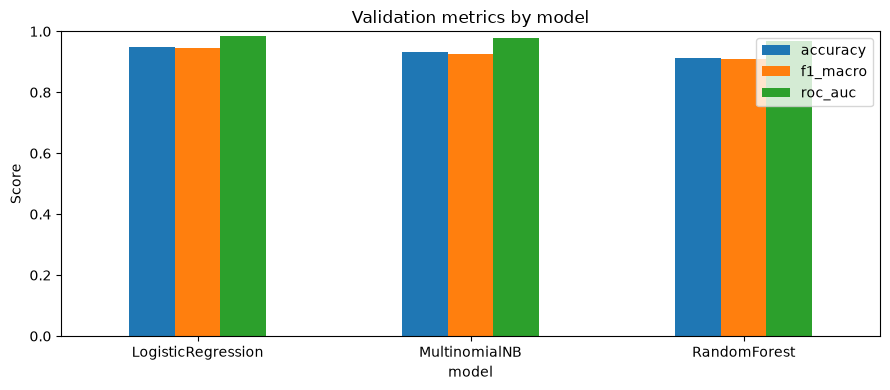

In [9]:
validation_rows = []
validation_predictions = {}
for name, search in searches.items():
    model = search.best_estimator_
    pred = model.predict(X_val)
    proba = model.predict_proba(X_val)[:, list(model.classes_).index('positive')]
    validation_predictions[name] = pred
    validation_rows.append({
        'model': name,
        'accuracy': accuracy_score(y_val, pred),
        'precision_macro': precision_score(y_val, pred, average='macro', zero_division=0),
        'recall_macro': recall_score(y_val, pred, average='macro', zero_division=0),
        'f1_macro': f1_score(y_val, pred, average='macro', zero_division=0),
        'roc_auc': roc_auc_score((y_val == 'positive').astype(int), proba),
    })

validation_results = pd.DataFrame(validation_rows).sort_values('f1_macro', ascending=False)
display(validation_results.round(4))
validation_results.to_csv(OUTPUT_DIR / 'validation_comparison.csv', index=False)

ax = validation_results.set_index('model')[['accuracy', 'f1_macro', 'roc_auc']].plot.bar(
    figsize=(9, 4), ylim=(0, 1), rot=0, title='Validation metrics by model'
)
ax.set_ylabel('Score')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'validation_comparison.png', dpi=160)
plt.show()

#### Confusion Matrix, ROC và phân tích lỗi

Best candidate (selected by validation Macro F1): LogisticRegression
              precision    recall  f1-score   support

    negative       0.95      0.96      0.96       895
    positive       0.94      0.92      0.93       545

    accuracy                           0.95      1440
   macro avg       0.95      0.94      0.94      1440
weighted avg       0.95      0.95      0.95      1440



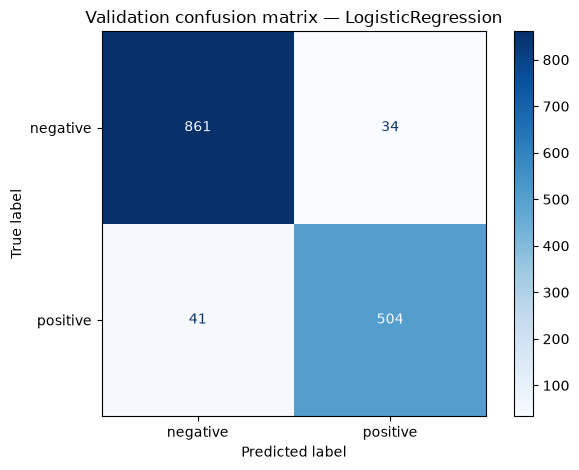

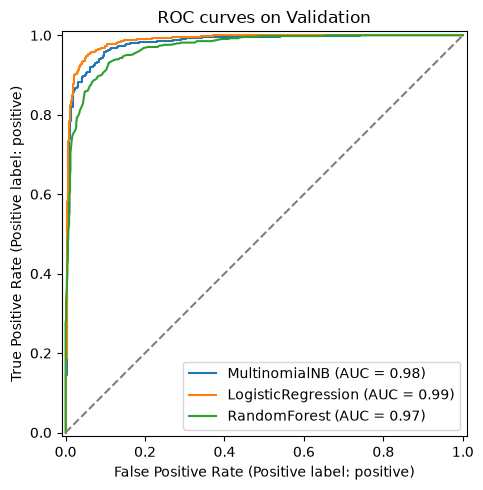

Validation errors: 75


,id,label,predicted_label,review_excerpt
6716,47594596546,negative,positive,Shop đóng gói cẩn thận. Đã sử dụng gần 1 tháng...
6748,91324830870,negative,positive,ko thích tuyệt vời giao siêu nhanh nên mua tư ...
6782,78511950244,positive,negative,Bao bì:dong goi can than
6784,78209388033,positive,negative,Chất lượng tốt lắm. Shop có thể đừng dùng keo ...
6795,13274968544,negative,positive,Công dụng:chuwa thaays Mùi hương:thơm nhẹ Lưu...
6810,86720002256,positive,negative,Xoá mất ảnh và video cũ dùng tạm của đơn mới í...
6817,75381467044,negative,positive,"Hương thơm:tot Lợi ích:tot Từng dùng, dùng tố..."
6823,85596684711,positive,negative,"Đã mua cái thứ 2 , 3 xị mà như hàng dyson :)))..."
6830,83456700596,positive,negative,Hương thơm:thơm Mẹo:k co Bao bì:don gian Mềm ...
6863,52660818358,positive,negative,"giá cả hạt dẻ, mùi thì ko thích lắm rjndgnsmdj..."


In [10]:
best_name = validation_results.iloc[0]['model']
best_model = searches[best_name].best_estimator_
best_pred = validation_predictions[best_name]
print('Best candidate (selected by validation Macro F1):', best_name)
print(classification_report(y_val, best_pred, labels=LABELS, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_val, best_pred, labels=LABELS, cmap='Blues')
plt.title(f'Validation confusion matrix — {best_name}')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'confusion_matrix.png', dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for name, search in searches.items():
    RocCurveDisplay.from_estimator(search.best_estimator_, X_val, y_val,
                                   pos_label='positive', name=name, ax=ax)
ax.plot([0, 1], [0, 1], '--', color='gray')
ax.set_title('ROC curves on Validation')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'roc_curves.png', dpi=160)
plt.show()

errors = val.loc[y_val.to_numpy() != best_pred].copy()
errors['predicted_label'] = best_pred[y_val.to_numpy() != best_pred]
errors['review_excerpt'] = errors['review'].str.slice(0, 200)
print('Validation errors:', len(errors))
display(errors[['id', 'label', 'predicted_label', 'review_excerpt']].head(15))
# Không tự động xuất toàn bộ review ra CSV công khai vì có thể chứa dữ liệu cá nhân.


#### Diễn giải đặc trưng (feature importance/ coefficients)

In [11]:
for name in ['MultinomialNB', 'LogisticRegression', 'RandomForest']:
    model = searches[name].best_estimator_
    features = model.named_steps['tfidf'].get_feature_names_out()
    clf = model.named_steps['classifier']
    if name == 'LogisticRegression':
        # coef_[0] ứng với classes_[1] trong bài toán nhị phân.
        values = clf.coef_[0]
        top_positive = np.argsort(values)[-15:][::-1]
        top_negative = np.argsort(values)[:15]
        print('\nLogisticRegression — positive-associated:', list(features[top_positive]))
        print('LogisticRegression — negative-associated:', list(features[top_negative]))
    elif name == 'MultinomialNB':
        pos_idx = list(clf.classes_).index('positive')
        neg_idx = list(clf.classes_).index('negative')
        log_odds = clf.feature_log_prob_[pos_idx] - clf.feature_log_prob_[neg_idx]
        print('\nMultinomialNB — positive-associated:', list(features[np.argsort(log_odds)[-15:][::-1]]))
        print('MultinomialNB — negative-associated:', list(features[np.argsort(log_odds)[:15]]))
    else:
        top = np.argsort(clf.feature_importances_)[-15:][::-1]
        print('\nRandomForest — most important:', list(features[top]))



MultinomialNB — positive-associated: ['phẩm tuyệt', 'shipper thân', 'rất ưng', 'okela', 'hihi', 'thận chất', 'chắn giao', 'thận sẽ', 'sữa thơm', 'bền màu', 'ok hình', 'mịn da', 'nhanh mua', 'nhanh săn', 'tình sẽ']
MultinomialNB — negative-associated: ['shop không', 'quá tệ', 'kém', 'lừa', 'lum', 'tùm', 'không cẩn', 'tùm lum', 'trả hàng', 'thả', 'hết cả', 'hàng bị', 'chỉ có', 'không hài', 'cẩu']

LogisticRegression — positive-associated: ['không bị', 'nhanh', 'thích', 'đẹp', 'thơm', 'ưng', 'hàng nhanh', 'mềm', 'xinh', 'nha', 'ok', 'ngon', 'tốt', 'sẽ', 'sẽ mua']
LogisticRegression — negative-associated: ['không', 'tệ', 'nhưng', 'mà', 'bị', 'chán', 'như', 'kém', 'móp', 'ra', 'thiếu', 'không giống', 'thì', 'không cẩn', 'cái']

RandomForest — most important: ['không', 'nhanh', 'hàng nhanh', 'thơm', 'đẹp', 'mà', 'tốt', 'giao hàng', 'giá', 'dụng', 'bị', 'chất', 'ok', 'hương', 'sẽ']


#### Lưu ứng viên và ghi chú

In [12]:
# Lưu mô hình ỨNG VIÊN theo Validation; chưa phải best_model.joblib cuối cùng.
model_path = OUTPUT_DIR / 'best_candidate_validation.joblib'
joblib.dump(best_model, model_path)
metadata = {
    'selection_metric': 'validation_macro_f1',
    'selected_model': best_name,
    'validation_metrics': validation_results.iloc[0].to_dict(),
    'train_samples': len(train),
    'validation_samples': len(val),
    'test_samples_reserved': len(test),
    'random_state': RANDOM_STATE,
    'cv_folds': CV_FOLDS,
}
with (OUTPUT_DIR / 'experiment_metadata.json').open('w', encoding='utf-8') as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)
print('Saved candidate:', model_path)
print('NEXT: lock parameters, train on Train+Validation if appropriate,')
print('evaluate exactly once on held-out Test in a separate final notebook,')
print('then export models/best_model.joblib and implement predict.py.')

Saved candidate: d:\Product Review Sentiment Analyst\results\milestone2\best_candidate_validation.joblib
NEXT: lock parameters, train on Train+Validation if appropriate,
evaluate exactly once on held-out Test in a separate final notebook,
then export models/best_model.joblib and implement predict.py.


#### Ghi chú

- ≥3 thuật toán: MultinomialNB, LogisticRegression, RandomForestClassifier.
- Pipeline: chuẩn hóa văn bản + TF-IDF trong TfidfVectorizer, sau đó classifier.
- Cross-validation: Stratified 5-Fold chỉ trên Train.
- Tuning: RandomizedSearchCV tối ưu Macro F1, chỉ trên Train.
- Đánh giá: Accuracy, Precision/Recall/F1 macro, ROC-AUC, Confusion Matrix, phân tích lỗi và đặc trưng.
- Test độc lập: giữ nguyên cho bước cuối; không truy cập nhãn Test để chọn mô hình.
- ColumnTransformer: phù hợp khi có nhiều cột đặc trưng khác loại; bài toán hiện chỉ sử dụng một cột văn bản, nên Pipeline với TF-IDF trực tiếp là cấu trúc tự nhiên.